# Fine-tuning PhoBERT with LoRA

PhoBERT-base-v2 from Hugging Face, fine-tuned by masked language modelling on sentences about what people eat and drink, and where (`data/food_sentences.csv`, from `data/make_food_sentences.py`): it learns what each food and drink is by guessing words hidden from it. With LoRA, PhoBERT's own weights stay as they are and only small added matrices in its attention are trained.

In [13]:
import unicodedata

import pandas as pd


def clean(text: str) -> str:
    """Lowercased, with only letters, numbers, punctuation and spaces: emoji and other symbols are dropped.
    NFC first, so each Vietnamese letter is one character, not a letter plus combining accent marks."""
    text = unicodedata.normalize("NFC", text)
    text = "".join(ch for ch in text if unicodedata.category(ch)[0] in "LNPZ")
    return " ".join(text.split()).lower()


# Sentences about what someone eats and drinks: "Tôi hay đi quán cà phê và uống matcha latte."
data = pd.read_csv("data/food_sentences.csv", usecols=["sentence"])
data["sentence"] = data["sentence"].map(clean)

print(f"{len(data)} sentences")
data.head()

10000 sentences


,sentence
0,lâu lắm rồi đồng nghiệp của mình chưa được ăn ...
1,"cả nhà mình rất thích nước dừa đá, tuần nào cũ..."
2,"tối qua, đứa bạn thân của tôi ăn một phần hột ..."
3,"giờ nghỉ trưa, anh uống một ly espresso ở laha..."
4,"ăn bingsu xoài xong, nhóm bạn của tôi hay gọi ..."


In [14]:
data.shape

(10000, 1)

In [15]:
from sklearn.model_selection import train_test_split

# 90% to train on, 10% held back to check it on sentences it hasn't seen
train, val = train_test_split(data, test_size=0.1, random_state=0)
print("training:", train.shape, "validation:", val.shape)

training: (9000, 1) validation: (1000, 1)


In [16]:
import torch
from transformers import AutoModelForMaskedLM, AutoTokenizer

PHOBERT = "vinai/phobert-base-v2"
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

# PhoBERT reads word-segmented text ("Trà_sữa trân_châu"): segment with underthesea's word_tokenize first.
# Inputs up to 256 tokens.
tokenizer = AutoTokenizer.from_pretrained(PHOBERT)
# On MPS (Apple GPUs) the default attention can't do dropout, which training needs: use the plain one there
attention = "eager" if device == "mps" else "sdpa"
# With its masked-word head: what it's fine-tuned on
model = AutoModelForMaskedLM.from_pretrained(PHOBERT, attn_implementation=attention).to(device)
model.train()  # dropout on, every weight trainable

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"{PHOBERT} on {device}: {trainable / 1e6:.0f}M trainable parameters")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

vinai/phobert-base-v2 on mps: 135M trainable parameters


In [17]:
from peft import LoraConfig, PeftModel, get_peft_model

# LoRA: PhoBERT's weights frozen, and next to each attention query and value layer a pair of small
# matrices (rank 8) that learn the change instead: well under 1% of the parameters to train
LORA = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.1, target_modules=["query", "value"])
if not isinstance(model, PeftModel):  # run twice, it would add LoRA on top of LoRA
    model = get_peft_model(model, LORA)
model.train()
model.print_trainable_parameters()

trainable params: 294,912 || all params: 135,358,721 || trainable%: 0.2179


In [18]:
from underthesea import word_tokenize

texts = ["Trà sữa trân châu đường đen", "Matcha latte ít ngọt, ngon xỉu"]
batch = tokenizer([word_tokenize(t, format="text") for t in texts], padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
print({name: tuple(tensor.shape) for name, tensor in batch.items()})  # input: (batch, seq_len)
with torch.no_grad():
    print("last_hidden_state:", tuple(model.roberta(**batch).last_hidden_state.shape))  # model.roberta: PhoBERT without the head  # output: (batch, seq_len, 768)

{'input_ids': (2, 11), 'attention_mask': (2, 11)}
last_hidden_state: (2, 11, 768)


In [19]:
from torch.utils.data import DataLoader
from transformers import DataCollatorForLanguageModeling


def encode(texts):
    """Word-segmented as PhoBERT expects and cut to its 256 tokens, not padded yet"""
    return [tokenizer(word_tokenize(t, format="text"), truncation=True, max_length=256) for t in texts]


# Pads each batch to its longest sentence, and hides 15% of the tokens, anywhere in it, for the model to guess
# (labels: the hidden ones)
collator = DataCollatorForLanguageModeling(tokenizer, mlm_probability=0.15)
train_loader = DataLoader(encode(train["sentence"]), batch_size=16, shuffle=True, collate_fn=collator)

# The validation sentences are masked once, so every check scores the same hidden words
torch.manual_seed(0)
val_batches = list(DataLoader(encode(val["sentence"]), batch_size=32, collate_fn=collator))

batch = next(iter(train_loader))
print(f"{len(train_loader)} training batches, {len(val_batches)} validation batches")
print({name: tuple(tensor.shape) for name, tensor in batch.items()})  # each (batch, seq_len)

563 training batches, 32 validation batches
{'input_ids': (16, 25), 'attention_mask': (16, 25), 'labels': (16, 25)}


In [20]:
import math

from peft import get_peft_model_state_dict, set_peft_model_state_dict
from tqdm.auto import tqdm
from transformers import get_linear_schedule_with_warmup

EPOCHS = 10  # at most: early stopping can end it sooner
EVAL_EVERY = 50  # training steps between validation checks
PATIENCE = 5  # validation checks in a row without a better loss before stopping
MIN_DELTA = 0.001  # how much lower the loss must be to count as better
# Only the LoRA matrices train, and at a higher learning rate than full fine-tuning (2e-5) would use
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=0.01)
steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=steps // 10, num_training_steps=steps)


@torch.no_grad()
def validation_loss():
    model.eval()
    losses = [model(**{k: v.to(device) for k, v in b.items()}).loss.item() for b in val_batches]
    model.train()
    return sum(losses) / len(losses)


def lora_weights():
    """A copy of the LoRA weights as they are now"""
    return {k: v.detach().clone() for k, v in get_peft_model_state_dict(model).items()}


def validate(step):
    """Checks the validation loss and keeps the weights if they're the best yet. True when it's time to stop."""
    loss = validation_loss()
    history["val"].append((step, loss))
    if loss < best["loss"] - MIN_DELTA:
        best.update(loss=loss, step=step, weights=lora_weights(), checks_since=0)
    else:
        best["checks_since"] += 1
    return best["checks_since"] >= PATIENCE


# For the graph: the loss of every training step, and (step, loss) of every validation check
history = {"train": [], "val": [(0, validation_loss())]}
best = {"loss": history["val"][0][1], "step": 0, "weights": lora_weights(), "checks_since": 0}
print(f"before: validation loss {best['loss']:.3f}")
step, stop = 0, False
for epoch in range(1, EPOCHS + 1):
    total, batches = 0.0, 0
    for batch in tqdm(train_loader, desc=f"epoch {epoch}"):
        loss = model(**{k: v.to(device) for k, v in batch.items()}).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
        step += 1
        batches += 1
        total += loss.item()
        history["train"].append(loss.item())
        if step % EVAL_EVERY == 0 and validate(step):
            stop = True
            break
    if not stop and history["val"][-1][0] != step:  # and at the end of every epoch
        stop = validate(step)
    val_loss = history["val"][-1][1]
    print(f"epoch {epoch}: training loss {total / batches:.3f}, validation loss {val_loss:.3f} (perplexity {math.exp(val_loss):.1f})")
    if stop:
        print(f"Stopped early: no better validation loss in the last {PATIENCE} checks")
        break

# Back to the best weights, not the last ones
set_peft_model_state_dict(model, best["weights"])
print(f"Kept the weights from step {best['step']} (epoch {math.ceil(best['step'] / len(train_loader))}): "
      f"validation loss {best['loss']:.3f}, perplexity {math.exp(best['loss']):.1f}")

before: validation loss 3.341


epoch 1:   0%|          | 0/563 [00:00<?, ?it/s]

epoch 1: training loss 2.625, validation loss 1.822 (perplexity 6.2)


epoch 2:   0%|          | 0/563 [00:00<?, ?it/s]

epoch 2: training loss 1.900, validation loss 1.556 (perplexity 4.7)


epoch 3:   0%|          | 0/563 [00:00<?, ?it/s]

epoch 3: training loss 1.678, validation loss 1.367 (perplexity 3.9)


epoch 4:   0%|          | 0/563 [00:00<?, ?it/s]

epoch 4: training loss 1.552, validation loss 1.289 (perplexity 3.6)


epoch 5:   0%|          | 0/563 [00:00<?, ?it/s]

epoch 5: training loss 1.505, validation loss 1.282 (perplexity 3.6)
Stopped early: no better validation loss in the last 5 checks
Kept the weights from step 2200 (epoch 4): validation loss 1.274, perplexity 3.6


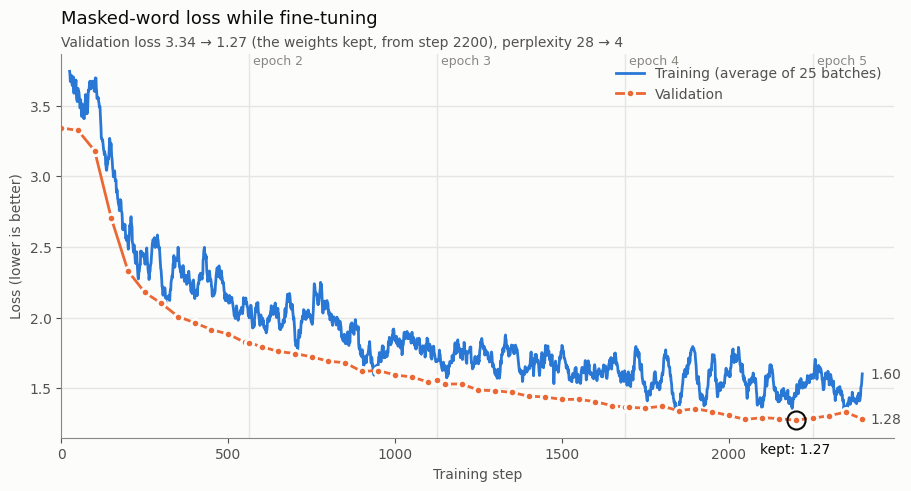

In [21]:
import matplotlib.pyplot as plt
import numpy as np

SURFACE, INK, INK_SECONDARY, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
TRAINING, VALIDATION = "#2a78d6", "#eb6834"
SMOOTH = 25  # batches averaged for the training line: one batch's loss alone is noisy

losses = np.array(history["train"])
smooth = min(SMOOTH, len(losses))
training = np.convolve(losses, np.ones(smooth) / smooth, mode="valid")
training_steps = np.arange(smooth, len(losses) + 1)
val_steps, val_losses = map(np.array, zip(*history["val"]))
per_epoch = len(train_loader)

fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE, layout="constrained")
ax.set_facecolor(SURFACE)
ax.plot(training_steps, training, color=TRAINING, linewidth=2, label=f"Training (average of {smooth} batches)")
ax.plot(val_steps, val_losses, color=VALIDATION, linewidth=2, marker="o", markersize=6,
        markeredgecolor=SURFACE, markeredgewidth=2, label="Validation")

# Where each epoch starts
for e in range(1, int(np.ceil(len(losses) / per_epoch))):
    ax.axvline(e * per_epoch, color=GRID, linewidth=1, zorder=0)
    ax.text(e * per_epoch, 1, f" epoch {e + 1}", transform=ax.get_xaxis_transform(), color=MUTED, fontsize=9, va="top")

# The weights kept: the best validation check
ax.plot(best["step"], best["loss"], marker="o", markersize=13, markerfacecolor="none", markeredgecolor=INK, markeredgewidth=1.5, zorder=4)
ax.annotate(f"kept: {best['loss']:.2f}", (best["step"], best["loss"]), xytext=(0, -16), textcoords="offset points",
            ha="center", va="top", color=INK, fontsize=10)

# The latest value at the end of each line
for x, y in [(training_steps[-1], training[-1]), (val_steps[-1], val_losses[-1])]:
    ax.annotate(f"{y:.2f}", (x, y), xytext=(6, 0), textcoords="offset points", va="center", color=INK_SECONDARY, fontsize=10)

start, end = val_losses[0], best["loss"]
ax.set_title("Masked-word loss while fine-tuning", loc="left", color=INK, fontsize=13, pad=22)
ax.text(0, 1.02, f"Validation loss {start:.2f} → {end:.2f} (the weights kept, from step {best['step']}), perplexity {np.exp(start):.0f} → {np.exp(end):.0f}",
        transform=ax.transAxes, color=INK_SECONDARY, fontsize=10)
ax.set_xlabel("Training step", color=INK_SECONDARY)
ax.set_ylabel("Loss (lower is better)", color=INK_SECONDARY)
ax.set_xlim(0, len(losses) * 1.04)
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(MUTED)
ax.tick_params(colors=INK_SECONDARY)
ax.legend(frameon=False, labelcolor=INK_SECONDARY, loc="upper right")
plt.show()

In [22]:
SAVE_TO = "models/phobert-lora"
model.save_pretrained(SAVE_TO)
tokenizer.save_pretrained(SAVE_TO)

('models/phobert-lora/tokenizer_config.json',
 'models/phobert-lora/vocab.txt',
 'models/phobert-lora/bpe.codes',
 'models/phobert-lora/added_tokens.json')